# Financial Transaction Fraud Detection using PySpark MLlib

---
## 1. Environment Setup

In [2]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure PySpark workers bind to the active Python binary
os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType, IntegerType, StructType, StructField
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, DecisionTreeClassifier, LinearSVC
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.functions import vector_to_array

# Initialize SparkSession with tuned memory and partition configs
spark = SparkSession.builder \
    .appName("CreditCardFraudDetection_PySpark") \
    .master("local[*]") \
    .config("spark.driver.memory", "4g") \
    .config("spark.sql.shuffle.partitions", "10") \
    .config("spark.driver.maxResultSize", "2g") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")


---
## 2. Distributed Data Ingestion & Schema Inspection


In [3]:
csv_path = os.path.join("..", "data", "creditcard.csv")
if not os.path.exists(csv_path):
    csv_path = os.path.join("data", "creditcard.csv")

t0 = time.time()
df = spark.read.csv(csv_path, header=True, inferSchema=True)
load_duration = time.time() - t0

total_rows = df.count()
total_cols = len(df.columns)

print(f"Data Ingestion Complete: {total_rows:,} records across {total_cols} columns loaded in {load_duration:.2f} seconds.")
df.printSchema()
df.show(5, truncate=False)


Data Ingestion Complete: 284,807 records across 31 columns loaded in 15.06 seconds.
root
 |-- Time: double (nullable = true)
 |-- V1: double (nullable = true)
 |-- V2: double (nullable = true)
 |-- V3: double (nullable = true)
 |-- V4: double (nullable = true)
 |-- V5: double (nullable = true)
 |-- V6: double (nullable = true)
 |-- V7: double (nullable = true)
 |-- V8: double (nullable = true)
 |-- V9: double (nullable = true)
 |-- V10: double (nullable = true)
 |-- V11: double (nullable = true)
 |-- V12: double (nullable = true)
 |-- V13: double (nullable = true)
 |-- V14: double (nullable = true)
 |-- V15: double (nullable = true)
 |-- V16: double (nullable = true)
 |-- V17: double (nullable = true)
 |-- V18: double (nullable = true)
 |-- V19: double (nullable = true)
 |-- V20: double (nullable = true)
 |-- V21: double (nullable = true)
 |-- V22: double (nullable = true)
 |-- V23: double (nullable = true)
 |-- V24: double (nullable = true)
 |-- V25: double (nullable = true)
 |-- V26:

---
## 3. Exploratory Data Analysis

In [4]:
# Quantify Class Distribution
class_counts = df.groupBy("Class").count().toPandas()
print("Class Distribution:")
print(class_counts)

legit_count = int(class_counts[class_counts["Class"] == 0]["count"].iloc[0])
fraud_count = int(class_counts[class_counts["Class"] == 1]["count"].iloc[0])
fraud_pct = (fraud_count / total_rows) * 100
imbalance_ratio = legit_count / fraud_count

print(f"\nSummary:")
print(f" - Legitimate Transactions (0): {legit_count:,} ({100-fraud_pct:.4f}%)")
print(f" - Fraudulent Transactions (1): {fraud_count:,} ({fraud_pct:.4f}%)")
print(f" - Imbalance Ratio: 1 fraud per {imbalance_ratio:.1f} normal transactions")

# Check for Null / NaN values across all columns
null_counts = df.select([F.count(F.when(F.col(c).isNull() | F.isnan(c), c)).alias(c) for c in df.columns]).toPandas()
print("\nMissing/Null Values Count across features:")
print(null_counts.T.rename(columns={0: "Null_Count"}).head(10))


Class Distribution:
   Class   count
0      0  284315
1      1     492

Summary:
 - Legitimate Transactions (0): 284,315 (99.8273%)
 - Fraudulent Transactions (1): 492 (0.1727%)
 - Imbalance Ratio: 1 fraud per 577.9 normal transactions

Missing/Null Values Count across features:
      Null_Count
Time           0
V1             0
V2             0
V3             0
V4             0
V5             0
V6             0
V7             0
V8             0
V9             0


In [5]:
# Transaction Amount Statistics by Class
print("Transaction Amount Distribution by Class:")
df.groupBy("Class").agg(
    F.count("Amount").alias("Count"),
    F.mean("Amount").alias("Mean_Amount"),
    F.stddev("Amount").alias("StdDev_Amount"),
    F.min("Amount").alias("Min_Amount"),
    F.max("Amount").alias("Max_Amount")
).show()


Transaction Amount Distribution by Class:
+-----+------+-----------------+------------------+----------+----------+
|Class| Count|      Mean_Amount|     StdDev_Amount|Min_Amount|Max_Amount|
+-----+------+-----------------+------------------+----------+----------+
|    0|284315|88.29102242231271|250.10509222589235|       0.0|  25691.16|
|    1|   492|122.2113211382114| 256.6832882977121|       0.0|   2125.87|
+-----+------+-----------------+------------------+----------+----------+



---
## 4. Feature Engineering

In [6]:
feature_cols = [f"V{i}" for i in range(1, 29)] + ["Amount", "Time"]

# Calculate balanced class weights
weight_fraud = total_rows / (2.0 * fraud_count)
weight_legit = total_rows / (2.0 * legit_count)
print(f"Cost-Sensitive Loss Weights -> Legit (0): {weight_legit:.4f} | Fraud (1): {weight_fraud:.4f}")

df_weighted = df.withColumn(
    "weight",
    F.when(F.col("Class") == 1, weight_fraud).otherwise(weight_legit)
)

assembler = VectorAssembler(inputCols=feature_cols, outputCol="raw_features")
scaler = StandardScaler(inputCol="raw_features", outputCol="scaled_features", withMean=True, withStd=True)

# Train-Test Partitioning (80% Train, 20% Test, Seed 42)
train_df, test_df = df_weighted.randomSplit([0.8, 0.2], seed=42)
train_df = train_df.cache()
test_df = test_df.cache()

print(f"Training Set:   {train_df.count():,} rows")
print(f"Testing Set:    {test_df.count():,} rows")

# Fit Feature Pipeline on Training Set only (preventing data leakage)
feature_pipeline = Pipeline(stages=[assembler, scaler])
feature_model = feature_pipeline.fit(train_df)

train_prepared = feature_model.transform(train_df).cache()
test_prepared = feature_model.transform(test_df).cache()
print("Feature preparation complete!")


Cost-Sensitive Loss Weights -> Legit (0): 0.5009 | Fraud (1): 289.4380
Training Set:   228,225 rows
Testing Set:    56,582 rows
Feature preparation complete!


---
## 5. Supervised Model Training & Evaluation
1. **Logistic Regression**
2. **Decision Tree Classifier** 
3. **Linear Support Vector Machine (LinearSVC)**

In [7]:
eval_roc = BinaryClassificationEvaluator(labelCol="Class", rawPredictionCol="rawPrediction", metricName="areaUnderROC")
eval_pr = BinaryClassificationEvaluator(labelCol="Class", rawPredictionCol="rawPrediction", metricName="areaUnderPR")

def compute_metrics(predictions, pred_col="prediction"):
    tp = predictions.filter(f"Class == 1 AND {pred_col} == 1.0").count()
    fp = predictions.filter(f"Class == 0 AND {pred_col} == 1.0").count()
    tn = predictions.filter(f"Class == 0 AND {pred_col} == 0.0").count()
    fn = predictions.filter(f"Class == 1 AND {pred_col} == 0.0").count()
    
    total = tp + fp + tn + fn
    acc = (tp + tn) / total
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0
    
    return {"TP": tp, "FP": fp, "TN": tn, "FN": fn, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1}

results = {}


In [8]:
# 1. Logistic Regression
print("Fitting Logistic Regression (Weighted Loss)...")
lr = LogisticRegression(featuresCol="scaled_features", labelCol="Class", weightCol="weight", maxIter=30, regParam=0.01)
t0 = time.time()
lr_model = lr.fit(train_prepared)
lr_time = time.time() - t0

lr_preds = lr_model.transform(test_prepared).cache()
m_lr = compute_metrics(lr_preds)
m_lr["ROC_AUC"] = eval_roc.evaluate(lr_preds)
m_lr["PR_AUC"] = eval_pr.evaluate(lr_preds)
m_lr["Train_Time_s"] = lr_time
results["Logistic Regression"] = m_lr

print(f"Logistic Regression ({lr_time:.2f}s): Recall={m_lr['Recall']:.4f}, Precision={m_lr['Precision']:.4f}, F1={m_lr['F1']:.4f}, ROC-AUC={m_lr['ROC_AUC']:.4f}")


Fitting Logistic Regression (Weighted Loss)...
Logistic Regression (17.37s): Recall=0.8252, Precision=0.1310, F1=0.2261, ROC-AUC=0.9750


In [9]:
# 2. Decision Tree Classifier
print("Fitting Decision Tree Classifier...")
dt = DecisionTreeClassifier(featuresCol="scaled_features", labelCol="Class", maxDepth=7, seed=42)
t0 = time.time()
dt_model = dt.fit(train_prepared)
dt_time = time.time() - t0

dt_preds = dt_model.transform(test_prepared).cache()
m_dt = compute_metrics(dt_preds)
m_dt["ROC_AUC"] = eval_roc.evaluate(dt_preds)
m_dt["PR_AUC"] = eval_pr.evaluate(dt_preds)
m_dt["Train_Time_s"] = dt_time
results["Decision Tree"] = m_dt

print(f"Decision Tree ({dt_time:.2f}s): Recall={m_dt['Recall']:.4f}, Precision={m_dt['Precision']:.4f}, F1={m_dt['F1']:.4f}, ROC-AUC={m_dt['ROC_AUC']:.4f}")


Fitting Decision Tree Classifier...
Decision Tree (5.03s): Recall=0.6990, Precision=0.8090, F1=0.7500, ROC-AUC=0.7472


In [10]:
# 3. Linear Support Vector Machine (LinearSVC)
print("Fitting Linear Support Vector Machine (Weighted Loss)...")
lsvc = LinearSVC(featuresCol="scaled_features", labelCol="Class", weightCol="weight", maxIter=25, regParam=0.01)
t0 = time.time()
lsvc_model = lsvc.fit(train_prepared)
lsvc_time = time.time() - t0

lsvc_preds = lsvc_model.transform(test_prepared).cache()
m_lsvc = compute_metrics(lsvc_preds)
m_lsvc["ROC_AUC"] = eval_roc.evaluate(lsvc_preds)
m_lsvc["PR_AUC"] = eval_pr.evaluate(lsvc_preds)
m_lsvc["Train_Time_s"] = lsvc_time
results["Linear SVM"] = m_lsvc

print(f"Linear SVM ({lsvc_time:.2f}s): Recall={m_lsvc['Recall']:.4f}, Precision={m_lsvc['Precision']:.4f}, F1={m_lsvc['F1']:.4f}, ROC-AUC={m_lsvc['ROC_AUC']:.4f}")


Fitting Linear Support Vector Machine (Weighted Loss)...
Linear SVM (10.99s): Recall=0.8252, Precision=0.1172, F1=0.2053, ROC-AUC=0.9759


---
## 6. Unsupervised Anomaly Exploration with K-Means

In [11]:
print("Fitting K-Means Clustering for Anomaly Scoring...")
kmeans = KMeans(featuresCol="scaled_features", predictionCol="cluster", k=4, seed=42, maxIter=20)
t0 = time.time()
km_model = kmeans.fit(train_prepared)
km_time = time.time() - t0

centers = [np.array(c) for c in km_model.clusterCenters()]
centers_bc = spark.sparkContext.broadcast(centers)

def get_dist(cluster_id, vec):
    c = centers_bc.value[int(cluster_id)]
    return float(np.linalg.norm(np.array(vec.toArray()) - c))

dist_udf = F.udf(get_dist, DoubleType())

km_train = km_model.transform(train_prepared).withColumn("dist_to_center", dist_udf(F.col("cluster"), F.col("scaled_features")))
km_test = km_model.transform(test_prepared).withColumn("dist_to_center", dist_udf(F.col("cluster"), F.col("scaled_features"))).cache()

# Compute 98.5th percentile threshold on training baseline
threshold = km_train.stat.approxQuantile("dist_to_center", [0.985], 0.001)[0]
print(f"Unsupervised Anomaly Distance Cutoff (98.5%): {threshold:.4f}")

km_test = km_test.withColumn("anomaly_pred", F.when(F.col("dist_to_center") >= threshold, 1.0).otherwise(0.0)).cache()
m_km = compute_metrics(km_test, pred_col="anomaly_pred")

eval_roc_dist = BinaryClassificationEvaluator(labelCol="Class", rawPredictionCol="dist_to_center", metricName="areaUnderROC")
eval_pr_dist = BinaryClassificationEvaluator(labelCol="Class", rawPredictionCol="dist_to_center", metricName="areaUnderPR")

m_km["ROC_AUC"] = eval_roc_dist.evaluate(km_test)
m_km["PR_AUC"] = eval_pr_dist.evaluate(km_test)
m_km["Train_Time_s"] = km_time
results["K-Means Anomaly Detector"] = m_km

print(f"K-Means Anomaly ({km_time:.2f}s): Recall={m_km['Recall']:.4f}, Precision={m_km['Precision']:.4f}, F1={m_km['F1']:.4f}, ROC-AUC={m_km['ROC_AUC']:.4f}")


Fitting K-Means Clustering for Anomaly Scoring...
Unsupervised Anomaly Distance Cutoff (98.5%): 12.1889
K-Means Anomaly (10.40s): Recall=0.6699, Precision=0.0756, F1=0.1358, ROC-AUC=0.9407


---
## 7. Model Comparison Table & Benchmark Analysis
We compile the empirical benchmark results across all four models.


In [12]:
comparison_table = pd.DataFrame(results).T[[
    "Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC", "TP", "FP", "TN", "FN", "Train_Time_s"
]]
print("=== COMPREHENSIVE MODEL COMPARISON BENCHMARK ===")
display(comparison_table.style.highlight_max(color='#d4edda', subset=["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]))


=== COMPREHENSIVE MODEL COMPARISON BENCHMARK ===


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,TP,FP,TN,FN,Train_Time_s
Logistic Regression,0.989714,0.130971,0.825243,0.226064,0.975040,0.639484,85.000000,564.000000,55915.000000,18.000000,17.366214
Decision Tree,0.999152,0.808989,0.699029,0.750000,0.747179,0.596607,72.000000,17.000000,56462.000000,31.000000,5.026008
Linear SVM,0.988371,0.117241,0.825243,0.205314,0.975902,0.600092,85.000000,640.000000,55839.000000,18.000000,10.985781
K-Means Anomaly Detector,0.984483,0.075575,0.669903,0.135827,0.940678,0.181032,69.000000,844.000000,55635.000000,34.000000,10.396317


---
## 8. Visualizations & Analytical Interpretations


<Figure size 1400x700 with 0 Axes>

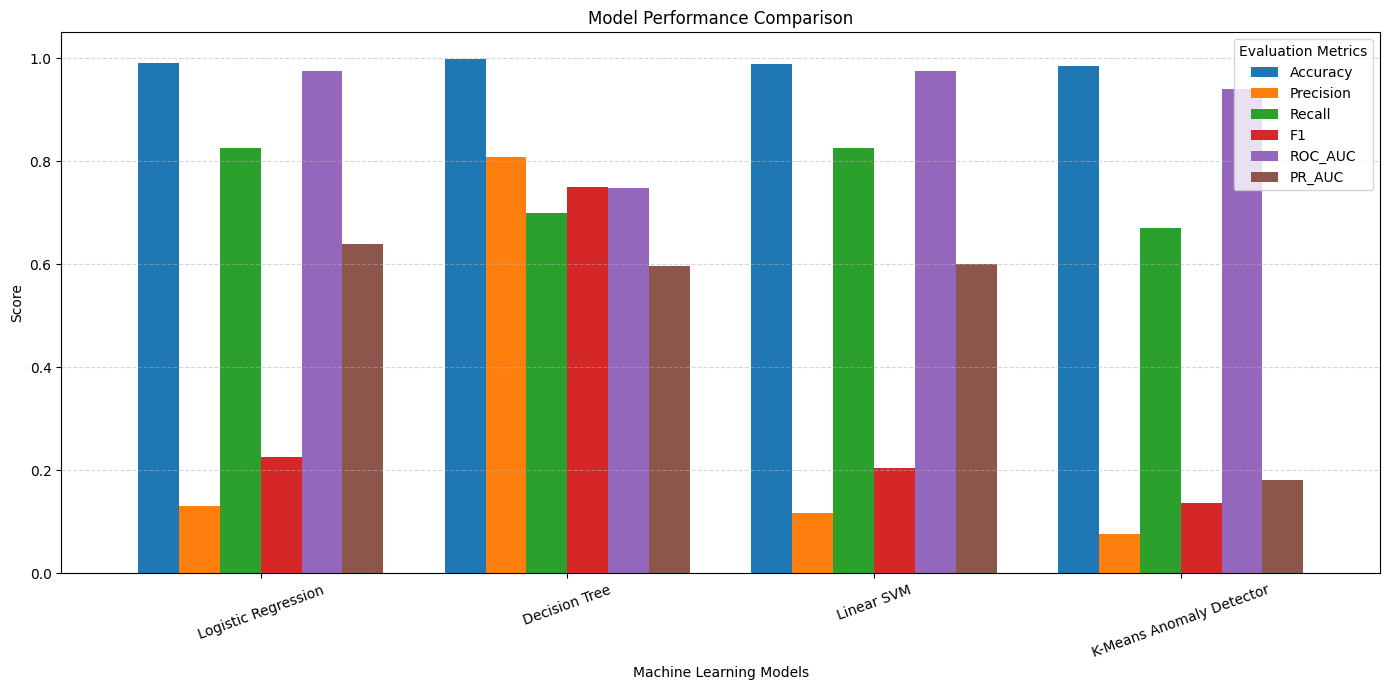

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]

plt.figure(figsize=(14, 7))

comparison_table[metrics].plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Metrics")
plt.xticks(rotation=20)
plt.ylim(0, 1.05)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

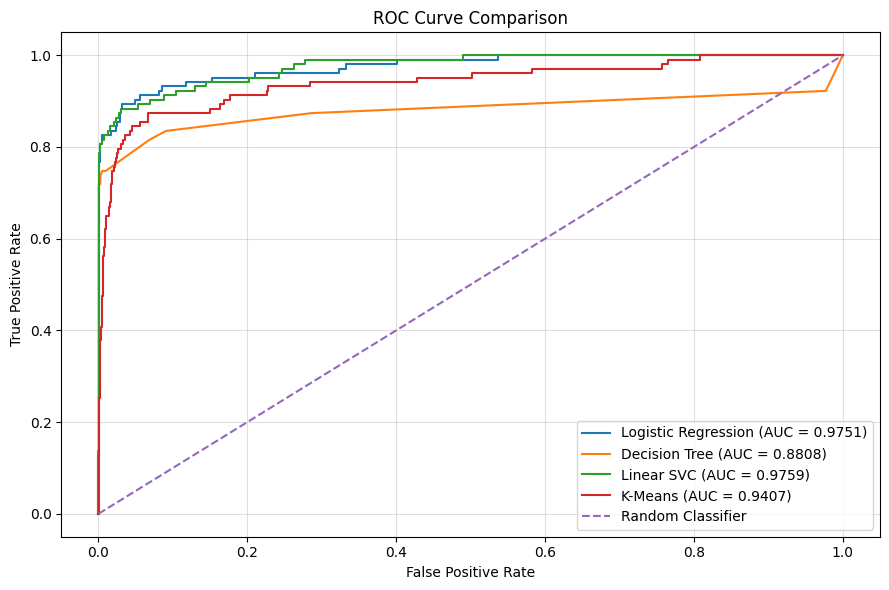

In [16]:
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

models = {
    "Logistic Regression": lr_preds,
    "Decision Tree": dt_preds,
    "Linear SVC": lsvc_preds,
    "K-Means": km_test
}

for name, predictions in models.items():

    if name == "K-Means":
        scores = predictions.select("Class", "dist_to_center").toPandas()
        y_score = scores["dist_to_center"].values

    elif name == "Decision Tree":
        scores = predictions.select(
            "Class",
            vector_to_array("probability")[1].alias("score")
        ).toPandas()
        y_score = scores["score"].values

    elif name == "Logistic Regression":
        scores = predictions.select(
            "Class",
            vector_to_array("probability")[1].alias("score")
        ).toPandas()
        y_score = scores["score"].values

    else:
        scores = predictions.select(
            "Class",
            "rawPrediction"
        ).toPandas()
        y_score = scores["rawPrediction"].apply(lambda x: float(x[1])).values

    y_true = scores["Class"].values

    fpr, tpr, thresholds = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

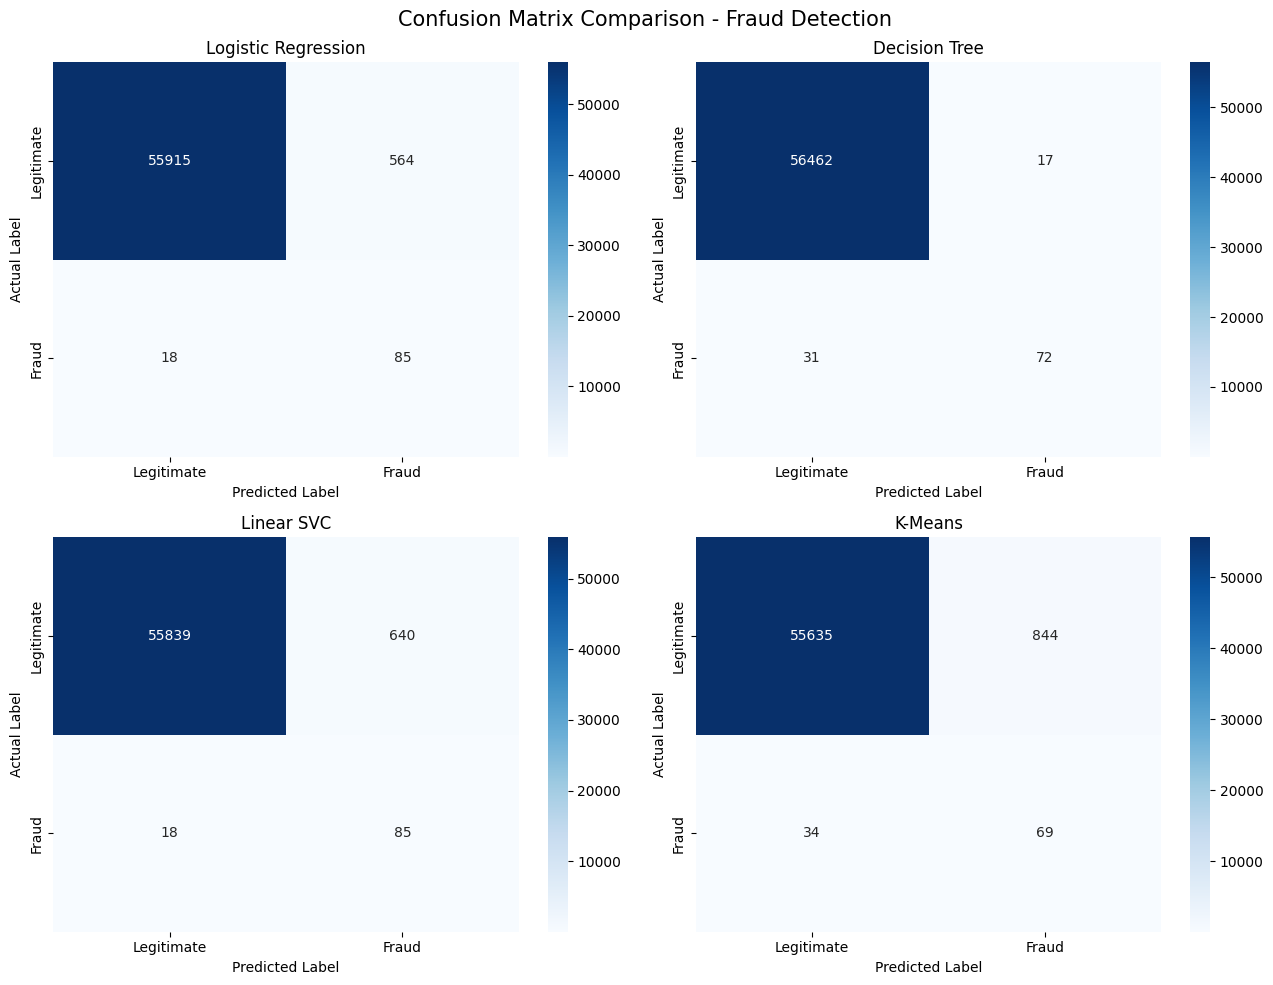

In [17]:
from sklearn.metrics import confusion_matrix


models = {
    "Logistic Regression": lr_preds,
    "Decision Tree": dt_preds,
    "Linear SVC": lsvc_preds,
    "K-Means": km_test
}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes = axes.flatten()

for i, (name, predictions) in enumerate(models.items()):

    if name == "K-Means":
        pred_col = "anomaly_pred"
    else:
        pred_col = "prediction"

    data = predictions.select("Class", pred_col).toPandas()

    y_true = data["Class"]
    y_pred = data[pred_col]

    cm = confusion_matrix(y_true, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=axes[i]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.suptitle("Confusion Matrix Comparison - Fraud Detection", fontsize=15)
plt.tight_layout()
plt.show()